# 03 – Feature Selection

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

After preprocessing, 280 sensors remain. Here we reduce them to **20–60 features** and compare four selection
methods plus PCA:

| Method | Type | Ranks features by |
|---|---|---|
| ANOVA F-test | filter, univariate, linear | difference in class means relative to within-class spread |
| Mutual information | filter, univariate, non-linear | any statistical dependence on the label |
| L1 logistic regression | embedded, multivariate | size of the coefficient that survives the L1 penalty |
| Random forest importance | embedded, multivariate, non-linear | mean impurity decrease across trees |
| PCA | feature *extraction* (not selection) | — builds new components from all sensors |

**Energy-aware angle:** selection keeps a subset of real sensors, so fewer sensors need to be monitored and
stored. PCA still needs *every* sensor measured to compute its components, so it gives no sensor saving and
is harder to interpret, even if it predicts well.

**No leakage:** everything here uses the **training set only**. Each method is compared inside
**time-ordered** cross-validation (`TimeSeriesSplit(4)`, `src/validation.py`), with the selector refitted in
every fold. The test set is not touched until 05_Evaluation.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so `src` works from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import time
from functools import partial

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectKBest, SelectFromModel, f_classif, mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

from src.config import RANDOM_STATE, MODELS_DIR
from src.data_loader import load_secom, split_xy
from src.preprocessing import time_train_test_split
from src.validation import time_cv
from src.plotting import apply_style, save_fig, CATEGORICAL, SEQUENTIAL_BLUES, REF_LINE_COLOR, TEXT_SECONDARY, SURFACE

np.random.seed(RANDOM_STATE)
apply_style()

pipeline_path = MODELS_DIR / 'preprocessing_pipeline.joblib'
if not pipeline_path.exists():
    raise FileNotFoundError('Run 02_Preprocessing.ipynb first to create ' + str(pipeline_path))
pipeline = joblib.load(pipeline_path)

df = load_secom()
train_df, test_df = time_train_test_split(df, test_size=0.2)
X_train_raw, y_train = split_xy(train_df)
X_train = pipeline.transform(X_train_raw)     # transform only - the pipeline was fitted in 02
print('Training set after preprocessing:', X_train.shape, f'| fails: {int(y_train.sum())}')

Training set after preprocessing: (1254, 280) | fails: 87


## 1. Define the selectors

All selectors keep the top *k* features by their score. Shared settings:

- `random_state = 42` everywhere; `class_weight='balanced'` for the model-based methods because fails are ~7%.
- L1 logistic regression uses `C = 0.1`, which leaves ~130 non-zero coefficients on the training set – enough to
  rank the top 60 by |coefficient|.

In [2]:
K_VALUES = [10, 20, 30, 40, 50, 60]
TARGET_MIN, TARGET_MAX = 20, 60

import sklearn
# scikit-learn >= 1.8 deprecates penalty='l1' in favour of l1_ratio=1; older versions need penalty='l1'
_SK_NEW = tuple(int(x) for x in sklearn.__version__.split('.')[:2]) >= (1, 8)
L1_ARGS = {'l1_ratio': 1} if _SK_NEW else {'penalty': 'l1'}

def l1_model():
    return LogisticRegression(**L1_ARGS, solver='liblinear', C=0.1, class_weight='balanced',
                              max_iter=5000, random_state=RANDOM_STATE)

def rf_model():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced_subsample',
                                  n_jobs=-1, random_state=RANDOM_STATE)

def make_selector(method, k):
    if method == 'ANOVA F-test':
        return SelectKBest(f_classif, k=k)
    if method == 'Mutual information':
        return SelectKBest(partial(mutual_info_classif, random_state=RANDOM_STATE), k=k)
    if method == 'L1 logistic':
        return SelectFromModel(l1_model(), max_features=k, threshold=-np.inf)
    if method == 'Random forest':
        return SelectFromModel(rf_model(), max_features=k, threshold=-np.inf)
    if method == 'PCA':
        return PCA(n_components=k, random_state=RANDOM_STATE)
    raise ValueError(method)

SELECTION_METHODS = ['ANOVA F-test', 'Mutual information', 'L1 logistic', 'Random forest']
ALL_METHODS = SELECTION_METHODS + ['PCA']
METHOD_COLORS = dict(zip(ALL_METHODS, CATEGORICAL))

## 2. Feature rankings on the full training set

Each method scores every feature once on the whole training set. These scores are used to inspect agreement
between methods and, at the end, to produce the final list. (Choosing *which* method and *how many* features
is done with cross-validation in section 3.)

In [3]:
t0 = time.time()
scores = pd.DataFrame(index=X_train.columns)
scores['ANOVA F-test'] = f_classif(X_train, y_train)[0]
scores['Mutual information'] = mutual_info_classif(X_train, y_train, random_state=RANDOM_STATE)
scores['L1 logistic'] = np.abs(l1_model().fit(X_train, y_train).coef_.ravel())
scores['Random forest'] = rf_model().fit(X_train, y_train).feature_importances_
print(f'Scored {len(scores)} features with 4 methods in {time.time() - t0:.1f} s')

ranks = scores.rank(ascending=False, method='first').astype(int)
print(f"L1 non-zero coefficients: {(scores['L1 logistic'] > 0).sum()}")
print('\nTop 10 features per method:')
print(pd.DataFrame({m: scores[m].sort_values(ascending=False).index[:10] for m in SELECTION_METHODS},
                   index=range(1, 11)).to_string())

Scored 280 features with 4 methods in 3.8 s
L1 non-zero coefficients: 130

Top 10 features per method:
   ANOVA F-test Mutual information L1 logistic Random forest
1          f059               f041        f059          f059
2          f247               f040        f460          f247
3          f103               f570        f205          f033
4          f510               f065        f333          f153
5          f205               f033        f033          f103
6          f290               f583        f099          f205
7          f033               f138        f280          f460
8          f152               f130        f485          f065
9          f028               f126        f486          f290
10         f346               f195        f056          f064


Jaccard overlap of top-40 sets:
                    ANOVA F-test  Mutual information  L1 logistic  Random forest
ANOVA F-test                1.00                0.16         0.25           0.36
Mutual information          0.16                1.00         0.08           0.23
L1 logistic                 0.25                0.08         1.00           0.23
Random forest               0.36                0.23         0.23           1.00

Features in the top 40 of all four methods (4): ['f033', 'f059', 'f172', 'f205']


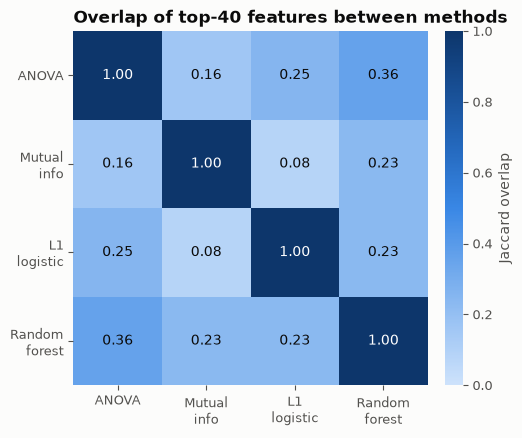

In [4]:
# Agreement between methods: Jaccard overlap of their top-40 feature sets
K_OVERLAP = 40
top_sets = {m: set(scores[m].sort_values(ascending=False).index[:K_OVERLAP]) for m in SELECTION_METHODS}
jac = pd.DataFrame(index=SELECTION_METHODS, columns=SELECTION_METHODS, dtype=float)
for a in SELECTION_METHODS:
    for b in SELECTION_METHODS:
        jac.loc[a, b] = len(top_sets[a] & top_sets[b]) / len(top_sets[a] | top_sets[b])
shared_all = set.intersection(*top_sets.values())
print(f'Jaccard overlap of top-{K_OVERLAP} sets:')
print(jac.round(2).to_string())
print(f'\nFeatures in the top {K_OVERLAP} of all four methods ({len(shared_all)}): {sorted(shared_all)}')

from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list('blues', SEQUENTIAL_BLUES)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(jac.values.astype(float), cmap=cmap, vmin=0, vmax=1)
short = ['ANOVA', 'Mutual\ninfo', 'L1\nlogistic', 'Random\nforest']
ax.set_xticks(range(4), short); ax.set_yticks(range(4), short)
for i in range(4):
    for j in range(4):
        v = jac.values[i, j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=10,
                color='white' if v > 0.55 else '#0b0b0b')
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.set_label('Jaccard overlap', color=TEXT_SECONDARY)
cb.outline.set_visible(False)
ax.set_title(f'Overlap of top-{K_OVERLAP} features between methods')
save_fig(fig, '03_method_overlap')
plt.show()

## 3. Cross-validated comparison (training set only)

For every method and every k in {10, 20, 30, 40, 50, 60}, we cross-validate **selector → logistic regression**
as one pipeline, so the selector is refitted inside each training fold and never sees the validation fold.

- **Classifier:** logistic regression with `class_weight='balanced'` – a simple, fast, common yardstick so
  differences come from the features, not from model tuning (tuning happens in 04_Modelling).
- **CV:** time-ordered `TimeSeriesSplit(4)`: each fold trains on the earliest wafers and validates on the next
  250 (20, 8, 9 and 11 fails), so a feature set is judged on how well it works on **later** wafers, as in real
  use. The first version of this notebook used shuffled `StratifiedKFold(5)`, which 05_Evaluation showed is
  optimistic because the process drifts over time; those results are kept in
  `outputs/models/feature_selection_cv_results_shuffled_cv.csv` and compared below.
- **Metrics:** PR-AUC (average precision; main metric for a rare fail class) and ROC-AUC.
- **Baseline:** the same classifier on all 280 preprocessed features.

In [5]:
cv = time_cv()      # TimeSeriesSplit(4): validate on later wafers only (X_train is sorted by time)
clf = lambda: LogisticRegression(class_weight='balanced', C=0.1, max_iter=5000, random_state=RANDOM_STATE)
scoring = {'pr_auc': 'average_precision', 'roc_auc': 'roc_auc'}

rows = []
t0 = time.time()
for method in ALL_METHODS:
    for k in K_VALUES:
        model = Pipeline([('select', make_selector(method, k)), ('clf', clf())])
        res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
        rows.append({'method': method, 'k': k,
                     'pr_auc_mean': res['test_pr_auc'].mean(), 'pr_auc_std': res['test_pr_auc'].std(),
                     'roc_auc_mean': res['test_roc_auc'].mean(), 'roc_auc_std': res['test_roc_auc'].std()})
    print(f'{method:<20} done ({time.time() - t0:.0f} s)')

base = cross_validate(clf(), X_train, y_train, cv=cv, scoring=scoring)
baseline = {'pr_auc_mean': base['test_pr_auc'].mean(), 'pr_auc_std': base['test_pr_auc'].std(),
            'roc_auc_mean': base['test_roc_auc'].mean(), 'roc_auc_std': base['test_roc_auc'].std()}
cv_results = pd.DataFrame(rows)
print(f"\nBaseline, all {X_train.shape[1]} features: PR-AUC {baseline['pr_auc_mean']:.3f} ± {baseline['pr_auc_std']:.3f}, "
      f"ROC-AUC {baseline['roc_auc_mean']:.3f} ± {baseline['roc_auc_std']:.3f}")
val_prev = np.mean([y_train.iloc[va].mean() for _, va in cv.split(X_train)])
print(f'Validation fail rate (PR-AUC of a random model): {val_prev:.3f}')

ANOVA F-test         done (1 s)


Mutual information   done (41 s)


L1 logistic          done (43 s)


Random forest        done (89 s)


PCA                  done (91 s)

Baseline, all 280 features: PR-AUC 0.104 ± 0.045, ROC-AUC 0.578 ± 0.076
Validation fail rate (PR-AUC of a random model): 0.048


In [6]:
pivot_pr = cv_results.pivot(index='k', columns='method', values='pr_auc_mean')[ALL_METHODS]
pivot_roc = cv_results.pivot(index='k', columns='method', values='roc_auc_mean')[ALL_METHODS]
print('Mean CV PR-AUC')
print(pivot_pr.round(3).to_string())
print('\nMean CV ROC-AUC')
print(pivot_roc.round(3).to_string())

# Compare with the earlier shuffled-CV version of this comparison
old = pd.read_csv(MODELS_DIR / 'feature_selection_cv_results_shuffled_cv.csv')
in_range = lambda d: d[d['k'].between(TARGET_MIN, TARGET_MAX)]
cmp = pd.DataFrame({
    'best PR-AUC, shuffled CV': in_range(old).groupby('method')['pr_auc_mean'].max(),
    'best PR-AUC, time-ordered CV': in_range(cv_results).groupby('method')['pr_auc_mean'].max(),
}).loc[ALL_METHODS]
print(f'\nBest PR-AUC in the 20-60 range: shuffled vs time-ordered CV '
      f'(all features: shuffled 0.150, time-ordered {baseline["pr_auc_mean"]:.3f})')
print(cmp.round(3).to_string())

Mean CV PR-AUC
method  ANOVA F-test  Mutual information  L1 logistic  Random forest    PCA
k                                                                          
10             0.115               0.058        0.109          0.103  0.107
20             0.122               0.053        0.060          0.113  0.066
30             0.113               0.060        0.069          0.120  0.063
40             0.117               0.093        0.063          0.113  0.065
50             0.096               0.075        0.070          0.119  0.056
60             0.097               0.091        0.069          0.111  0.054

Mean CV ROC-AUC
method  ANOVA F-test  Mutual information  L1 logistic  Random forest    PCA
k                                                                          
10             0.623               0.472        0.521          0.615  0.541
20             0.601               0.454        0.557          0.600  0.513
30             0.588               0.504        0.518   

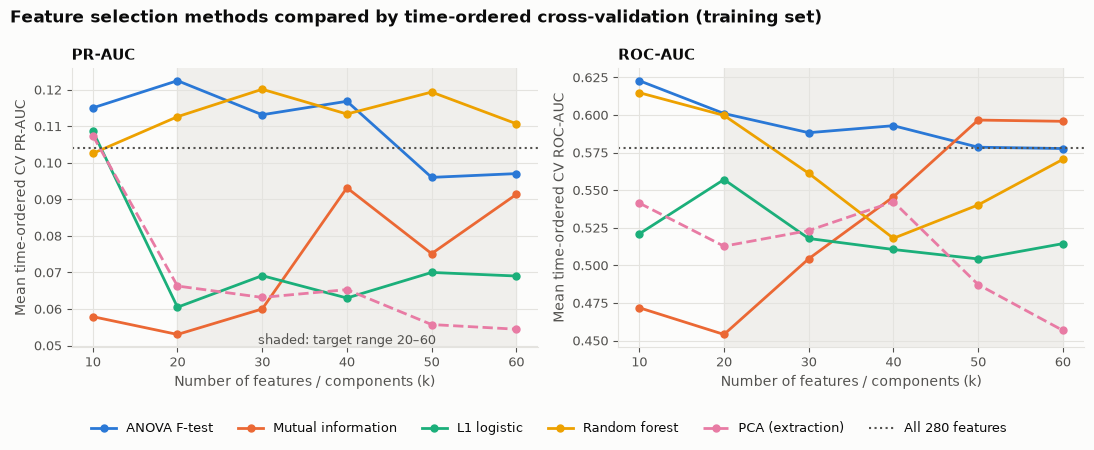

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharex=True)
for ax, metric, label in [(axes[0], 'pr_auc', 'PR-AUC'), (axes[1], 'roc_auc', 'ROC-AUC')]:
    ax.axvspan(TARGET_MIN, TARGET_MAX, color='#f0efec', zorder=0)
    for m in ALL_METHODS:
        d = cv_results[cv_results['method'] == m]
        ax.plot(d['k'], d[f'{metric}_mean'], marker='o', markersize=5, color=METHOD_COLORS[m],
                linestyle='--' if m == 'PCA' else '-', label=m + (' (extraction)' if m == 'PCA' else ''))
    ax.axhline(baseline[f'{metric}_mean'], color=REF_LINE_COLOR, linestyle=':', linewidth=1.5,
               label=f'All {X_train.shape[1]} features')
    ax.set_xticks(K_VALUES)
    ax.set_xlabel('Number of features / components (k)')
    ax.set_ylabel(f'Mean time-ordered CV {label}')
    ax.set_title(label, fontsize=11)
axes[0].text((TARGET_MIN + TARGET_MAX) / 2, axes[0].get_ylim()[0], 'shaded: target range 20–60', ha='center',
             va='bottom', fontsize=9, color=TEXT_SECONDARY)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=6, bbox_to_anchor=(0.5, -0.06), fontsize=9)
fig.suptitle('Feature selection methods compared by time-ordered cross-validation (training set)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(rect=(0, 0.04, 1, 1))
save_fig(fig, '03_cv_scores_vs_k')
plt.show()

**Reading the comparison**

- **Only two methods carry over to later wafers.** ANOVA F-test (best: 0.122 at k = 20) and random-forest
  importance (0.111–0.120 at every k from 20 to 60) beat the all-280-features baseline (0.104). Random forest
  is above it at every k; ANOVA only up to k = 40.
- **L1 logistic, mutual information and PCA fall below the baseline** in the 20–60 range (PR-AUC 0.05–0.09).
  Mutual information at k = 20 (0.053) is close to a random model (0.048); its nearest-neighbour estimates are
  noisy with only 87 fails, and the L1 and PCA combinations learned on early wafers do not transfer.
- **Every number is lower than with shuffled CV** (ANOVA's best was 0.216 there) because each fold now has to
  predict later wafers after the process has drifted; the comparison table above shows this for all methods.
- Fold-to-fold spread is large (SD ≈ 0.03–0.08 PR-AUC), so differences of a few hundredths are **not
  significant**. That is why the choice below uses a one-standard-error rule instead of the single best number.
- The methods agree poorly on *which* features matter (top-40 Jaccard overlap 0.08–0.36): the fault signal is
  spread over many weak, partly redundant sensors.

## 4. PCA: how many components carry the variance?

80% of variance needs 104 components
90% of variance needs 143 components
95% of variance needs 173 components
20 components explain 34.4% of variance
40 components explain 50.9% of variance
60 components explain 62.8% of variance


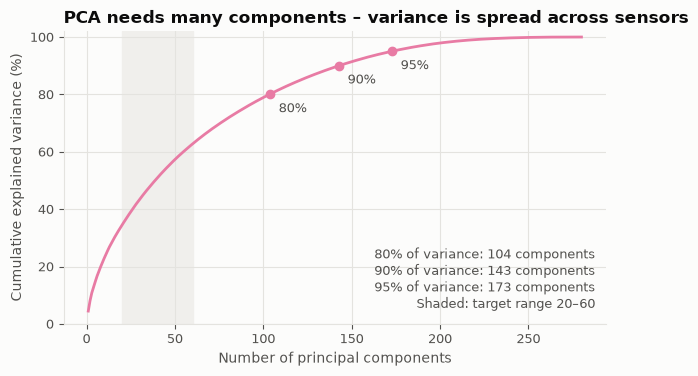

In [8]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_train)
cum = np.cumsum(pca_full.explained_variance_ratio_)
n_for = {t: int(np.searchsorted(cum, t) + 1) for t in (0.80, 0.90, 0.95)}
for t, n in n_for.items():
    print(f'{t:.0%} of variance needs {n} components')
for k in (20, 40, 60):
    print(f'{k} components explain {cum[k - 1]:.1%} of variance')

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(np.arange(1, len(cum) + 1), cum * 100, color=CATEGORICAL[4])
ax.axvspan(TARGET_MIN, TARGET_MAX, color='#f0efec', zorder=0)
for t, n in n_for.items():
    ax.plot([n], [t * 100], marker='o', markersize=6, color=CATEGORICAL[4])
    ax.annotate(f'{t:.0%}', (n, t * 100), xytext=(6, -6), textcoords='offset points',
                ha='left', va='top', fontsize=9, color=TEXT_SECONDARY)
ax.text(0.98, 0.04, '\n'.join(f'{t:.0%} of variance: {n} components' for t, n in n_for.items())
        + f'\nShaded: target range {TARGET_MIN}–{TARGET_MAX}',
        transform=ax.transAxes, ha='right', va='bottom', fontsize=9, color=TEXT_SECONDARY)
ax.set_xlabel('Number of principal components')
ax.set_ylabel('Cumulative explained variance (%)')
ax.set_ylim(0, 102)
ax.set_title('PCA needs many components – variance is spread across sensors')
save_fig(fig, '03_pca_explained_variance')
plt.show()

In the 20–60 range PCA keeps only about a third to two-thirds of the variance, and its best time-ordered CV
PR-AUC in that range (0.066) is far below ANOVA and random forest, and below using all features. Combined with needing all sensors measured and producing components that
cannot be traced back to a single sensor, PCA is a useful comparison but not the final choice.

## 5. Choose the method and number of features

Rule (decided before looking at the numbers):

1. Only **selection** methods are eligible for the final list (PCA cannot give a sensor subset), and only
   k in the 20–60 target range.
2. Take the configuration with the highest mean CV PR-AUC.
3. **One-standard-error rule:** among configurations whose mean PR-AUC is within one standard error of the best,
   pick the one with the **fewest features** (fewer sensors to monitor = lower energy and cost). Ties on k go to
   the higher PR-AUC.

In [9]:
n_folds = cv.get_n_splits()
eligible = cv_results[cv_results['method'].isin(SELECTION_METHODS) & cv_results['k'].between(TARGET_MIN, TARGET_MAX)].copy()
best = eligible.loc[eligible['pr_auc_mean'].idxmax()]
se = best['pr_auc_std'] / np.sqrt(n_folds)
within = eligible[eligible['pr_auc_mean'] >= best['pr_auc_mean'] - se]
chosen = within.sort_values(['k', 'pr_auc_mean'], ascending=[True, False]).iloc[0]

pca_best = cv_results[(cv_results['method'] == 'PCA') & cv_results['k'].between(TARGET_MIN, TARGET_MAX)] \
    .sort_values('pr_auc_mean', ascending=False).iloc[0]

print(f"Best eligible : {best['method']}, k={best['k']}, PR-AUC {best['pr_auc_mean']:.3f} (SE {se:.3f})")
print(f"Within 1 SE   : {len(within)} configurations")
print(f"CHOSEN        : {chosen['method']}, k={int(chosen['k'])}, "
      f"PR-AUC {chosen['pr_auc_mean']:.3f} ± {chosen['pr_auc_std']:.3f}, ROC-AUC {chosen['roc_auc_mean']:.3f}")
print(f"Best PCA      : k={int(pca_best['k'])}, PR-AUC {pca_best['pr_auc_mean']:.3f}, ROC-AUC {pca_best['roc_auc_mean']:.3f}")
print(f"All features  : PR-AUC {baseline['pr_auc_mean']:.3f}, ROC-AUC {baseline['roc_auc_mean']:.3f}")

Best eligible : ANOVA F-test, k=20, PR-AUC 0.122 (SE 0.039)
Within 1 SE   : 12 configurations
CHOSEN        : ANOVA F-test, k=20, PR-AUC 0.122 ± 0.077, ROC-AUC 0.601
Best PCA      : k=20, PR-AUC 0.066, ROC-AUC 0.513
All features  : PR-AUC 0.104, ROC-AUC 0.578


In [10]:
CHOSEN_METHOD, CHOSEN_K = chosen['method'], int(chosen['k'])

# Fit the chosen selector on the full training set to get the final list
final_selector = make_selector(CHOSEN_METHOD, CHOSEN_K).fit(X_train, y_train)
selected_features = list(X_train.columns[final_selector.get_support()])

# Order by the chosen method's score and add agreement with the other methods
sel_scores = scores.loc[selected_features].sort_values(CHOSEN_METHOD, ascending=False)
selected_features = list(sel_scores.index)
agreement = pd.Series({f: sum(ranks.loc[f, m] <= CHOSEN_K for m in SELECTION_METHODS) for f in selected_features})

print(f'{len(selected_features)} features selected by {CHOSEN_METHOD} '
      f'({len(selected_features) / 590:.1%} of the original 590 sensors)')
print(f'Selected features also in the top {CHOSEN_K} of all 4 methods: {int((agreement == 4).sum())}, '
      f'of >= 3 methods: {int((agreement >= 3).sum())}')
print(selected_features)

20 features selected by ANOVA F-test (3.4% of the original 590 sensors)
Selected features also in the top 20 of all 4 methods: 1, of >= 3 methods: 8
['f059', 'f247', 'f103', 'f510', 'f205', 'f290', 'f033', 'f152', 'f028', 'f346', 'f021', 'f129', 'f079', 'f333', 'f155', 'f460', 'f160', 'f000', 'f197', 'f125']


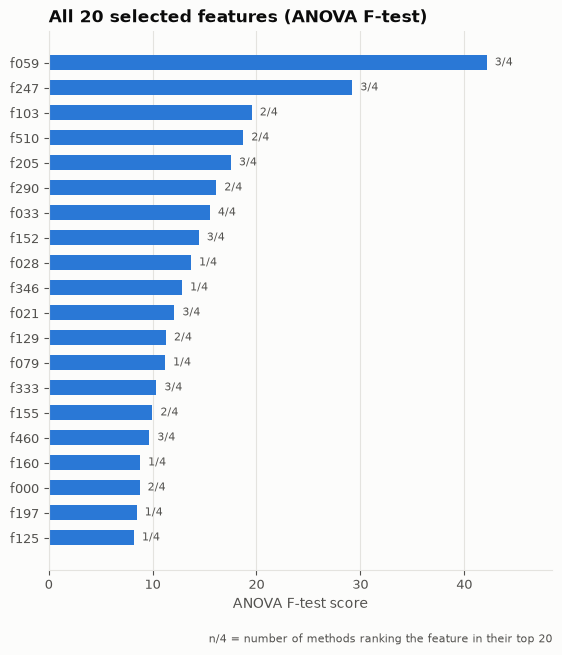

In [11]:
n_show = min(20, len(selected_features))
top = sel_scores[CHOSEN_METHOD].head(n_show)[::-1]
agree_top = agreement[top.index]

fig, ax = plt.subplots(figsize=(6.5, 0.28 * n_show + 1.4))
ax.barh(top.index, top.values, color=METHOD_COLORS[CHOSEN_METHOD], height=0.6)
for i, (f, v) in enumerate(top.items()):
    ax.text(v, i, f'  {agree_top[f]}/4', va='center', fontsize=8, color=TEXT_SECONDARY)
ax.set_xlim(0, top.max() * 1.15)
ax.set_xlabel(f'{CHOSEN_METHOD} score')
ax.set_title((f'All {n_show} selected features' if n_show == len(selected_features)
              else f'Top {n_show} of {len(selected_features)} selected features') + f' ({CHOSEN_METHOD})')
ax.text(1.0, -0.12 - 0.3 / n_show, 'n/4 = number of methods ranking the feature in their top '
        f'{CHOSEN_K}', transform=ax.transAxes, ha='right', fontsize=8, color=TEXT_SECONDARY)
ax.grid(axis='y', visible=False)
save_fig(fig, '03_selected_features')
plt.show()

The rule picks **ANOVA F-test with 20 features**: the best mean PR-AUC in the target range, and also the fewest
features, i.e. about 3% of the original 590 sensors. This is the same choice the earlier shuffled-CV version
made, so the feature list did not change. Random forest is a close second (0.120 at k = 30) and more stable
across folds, so its list is a reasonable alternative; `feature_rankings.csv` has every method's ranking.

## 6. Save the selected feature list and comparison results

In [12]:
out = {
    'random_state': RANDOM_STATE,
    'method': CHOSEN_METHOD,
    'k': CHOSEN_K,
    'selection_rule': 'max mean time-ordered CV (TimeSeriesSplit(4)) PR-AUC over selection methods with 20<=k<=60, '
                      'then fewest features within 1 standard error',
    'cv_pr_auc_mean': round(float(chosen['pr_auc_mean']), 4),
    'cv_pr_auc_std': round(float(chosen['pr_auc_std']), 4),
    'cv_roc_auc_mean': round(float(chosen['roc_auc_mean']), 4),
    'baseline_all_features_pr_auc': round(float(baseline['pr_auc_mean']), 4),
    'n_features_after_preprocessing': int(X_train.shape[1]),
    'selected_features': selected_features,
    'usage': 'X_sel = joblib.load("outputs/models/preprocessing_pipeline.joblib").transform(X)[selected_features]',
}
features_path = MODELS_DIR / 'selected_features.json'
features_path.write_text(json.dumps(out, indent=2))

cv_path = MODELS_DIR / 'feature_selection_cv_results.csv'
cv_results.round(4).to_csv(cv_path, index=False)

rank_path = MODELS_DIR / 'feature_rankings.csv'
scores.join(ranks, rsuffix=' rank').sort_values(f'{CHOSEN_METHOD} rank').to_csv(rank_path)

for p in (features_path, cv_path, rank_path):
    print('Saved', p.relative_to(ROOT))

Saved outputs\models\selected_features.json
Saved outputs\models\feature_selection_cv_results.csv
Saved outputs\models\feature_rankings.csv


### Summary

In [13]:
summary = pd.DataFrame({
    'Item': ['Features after preprocessing', 'Chosen method', 'Selected features (k)',
             'Share of original 590 sensors', 'CV PR-AUC (chosen)', 'CV PR-AUC (all features)',
             'CV PR-AUC (best PCA in 20-60)', 'CV ROC-AUC (chosen)', 'PCA components for 90% variance'],
    'Value': [X_train.shape[1], CHOSEN_METHOD, CHOSEN_K, f'{CHOSEN_K / 590:.1%}',
              f"{chosen['pr_auc_mean']:.3f} ± {chosen['pr_auc_std']:.3f}",
              f"{baseline['pr_auc_mean']:.3f} ± {baseline['pr_auc_std']:.3f}",
              f"{pca_best['pr_auc_mean']:.3f} (k={int(pca_best['k'])})",
              f"{chosen['roc_auc_mean']:.3f}", n_for[0.90]],
})
w = summary['Item'].str.len().max()
for i, v in zip(summary['Item'], summary['Value']):
    print(f'{i:<{w}}  {v}')

Features after preprocessing     280
Chosen method                    ANOVA F-test
Selected features (k)            20
Share of original 590 sensors    3.4%
CV PR-AUC (chosen)               0.122 ± 0.077
CV PR-AUC (all features)         0.104 ± 0.045
CV PR-AUC (best PCA in 20-60)    0.066 (k=20)
CV ROC-AUC (chosen)              0.601
PCA components for 90% variance  143


**Next (04_Modelling):** load the pipeline and `selected_features.json`, apply
`pipeline.transform(X)[selected_features]` to train and test, and tune the classifiers on the selected features.